# What does the fungal growth dataset contain?

**Start with the growth heatmap:** each cell is one organism/strain in one medium. Then compare the reported relative-control response and inspect what is recorded about the media.

The source is [Growth_data_for_ML_Helsinki_Uni.csv](metabolic_models/Growth_data_for_ML_Helsinki_Uni.csv). These are **experimental summaries**, separate from the simulations in [fungi_exploration.ipynb](fungi_exploration.ipynb).

Run from the repository root. This notebook reads the CSV without changing it. Units and processing definitions have not been supplied; figure labels retain the source metric names.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import HTML, display

csv_path = Path("metabolic_models/Growth_data_for_ML_Helsinki_Uni.csv")
data = pd.read_csv(csv_path)
response_columns = ["AUC", "NetAUC_sandra", "AUC_sandra", "growth_max",
                    "growth_max_sandra", "Biomass", "Net_Biomass", "Relative_control"]
process_columns = ["Temperature", "Time", "Dilution"]
chemical_columns = [col for col in data if col not in
                    ["organism_id", "medium_id", *response_columns, *process_columns]]
organisms = data["organism_id"].drop_duplicates().tolist()
media_order = data["medium_id"].drop_duplicates().tolist()
assert not data.duplicated(["organism_id", "medium_id"]).any()
assert len(data) == len(organisms) * len(media_order)
assert data.groupby("medium_id")[[*process_columns, *chemical_columns]].nunique().le(1).all().all()
raw_data = data.copy(deep=True)
for column in response_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")
original_fit_failed = raw_data["growth_max"].eq("cannot fit data")

plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
def show_table(frame):
    display(HTML('<div style="max-height:420px;overflow:auto">' +
                 frame.to_html(index=False, escape=True, border=0) + '</div>'))

show_table(pd.DataFrame({
    "What": ["Organism/strain labels", "Media", "Organism × medium rows",
             "Growth-summary columns", "Recorded chemical columns", "Original growth fits that failed"],
    "Count": [len(organisms), len(media_order), len(data), len(response_columns),
              len(chemical_columns), int(original_fit_failed.sum())],
}))

What,Count
Organism/strain labels,12
Media,29
Organism × medium rows,348
Growth-summary columns,8
Recorded chemical columns,25
Original growth fits that failed,18


## 1. Growth across organisms and media

Colour shows **`growth_max_sandra`**, a reported maximum-growth summary. Brighter cells have larger values on a shared scale. Units and the difference from `growth_max` need confirmation; this metric is the initial overview because all 348 entries are numeric.

**× means the original `growth_max` fit says “cannot fit data”.** The Sandra value is still displayed, but its reliability is unresolved. A recorded zero is displayed as zero; it is not independently confirmed absence of growth. There are no replicate uncertainties or raw growth curves in this file.

Columns follow the CSV order and have short labels. The full medium labels are listed below the growth views. Organism labels retain strain identifiers.

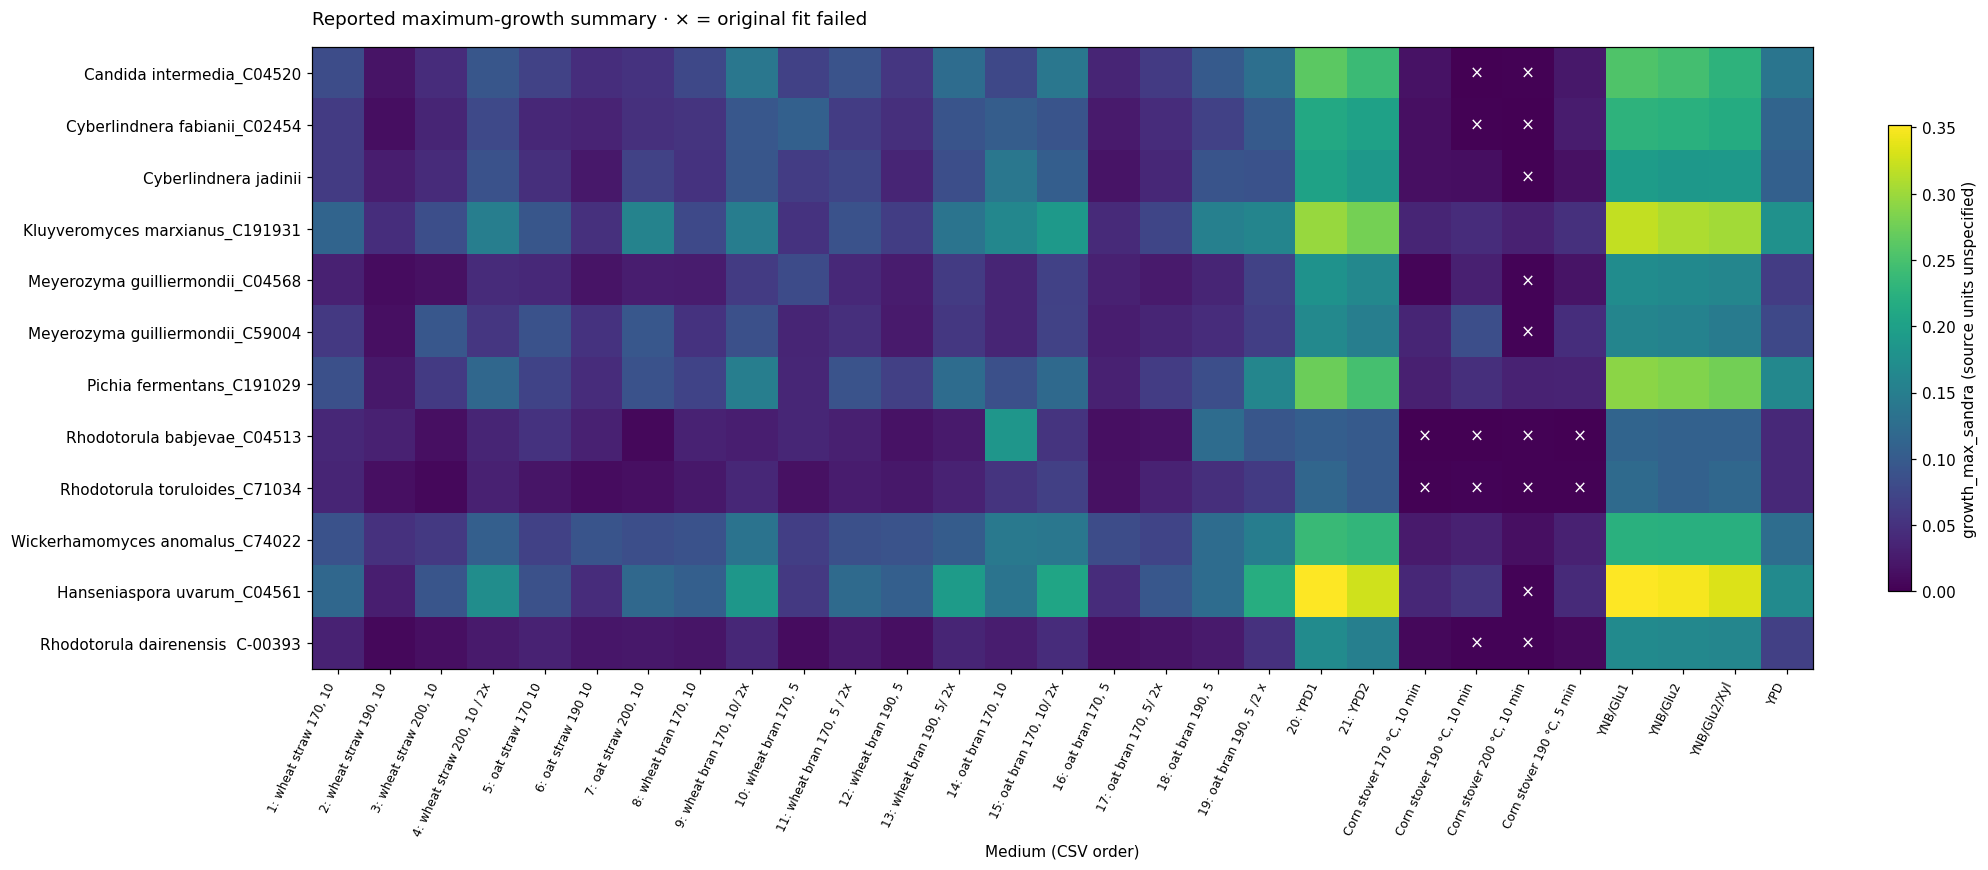

In [2]:
def medium_label(name):
    if name.startswith("Medium "):
        number = name.split()[1].split("(")[0]
        description = name.split("(", 1)[1].rstrip(")")
        return f"{number}: {description}"
    return name.replace("Corn stover (FIN), ", "Corn stover ")

medium_labels = [medium_label(name) for name in media_order]

def matrix_for(metric):
    return data.pivot(index="organism_id", columns="medium_id", values=metric).reindex(
        index=organisms, columns=media_order)

failed_matrix = (raw_data.assign(failed=original_fit_failed)
                 .pivot(index="organism_id", columns="medium_id", values="failed")
                 .reindex(index=organisms, columns=media_order).to_numpy())

def growth_heatmap(metric, title, relative=False):
    matrix = matrix_for(metric)
    fig, ax = plt.subplots(figsize=(18, 7.8), layout="constrained")
    kwargs = {"norm": TwoSlopeNorm(vmin=0, vcenter=1,
                vmax=max(1.01, float(np.nanmax(matrix.to_numpy())))), "cmap": "BrBG"} if relative else {
                "vmin": 0, "cmap": "viridis"}
    cmap = plt.get_cmap(kwargs.pop("cmap")).copy()
    cmap.set_bad("#cccccc")
    im = ax.imshow(matrix.to_numpy(), aspect="auto", cmap=cmap, **kwargs)
    ax.set_xticks(range(len(media_order)), medium_labels, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(organisms)), organisms)
    ax.set_xlabel("Medium (CSV order)")
    ax.set_title(title, loc="left", pad=15)
    if metric in ["growth_max", "growth_max_sandra"]:
        for row, col in zip(*np.where(failed_matrix)):
            ax.text(col, row, "×", ha="center", va="center", color="white", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.75, label=metric + (" (reported ratio)" if relative else " (source units unspecified)"))
    plt.show()

growth_heatmap("growth_max_sandra", "Reported maximum-growth summary · × = original fit failed")

## 2. Reported response relative to the control

`Relative_control` equals **1 for all 12 YPD rows**. The colour scale centres on 1: lower values are below that reference and higher values above it. This is a separate reported response, **not a normalization of the growth metric above**. The source does not specify its formula or whether control denominators differ between batches.

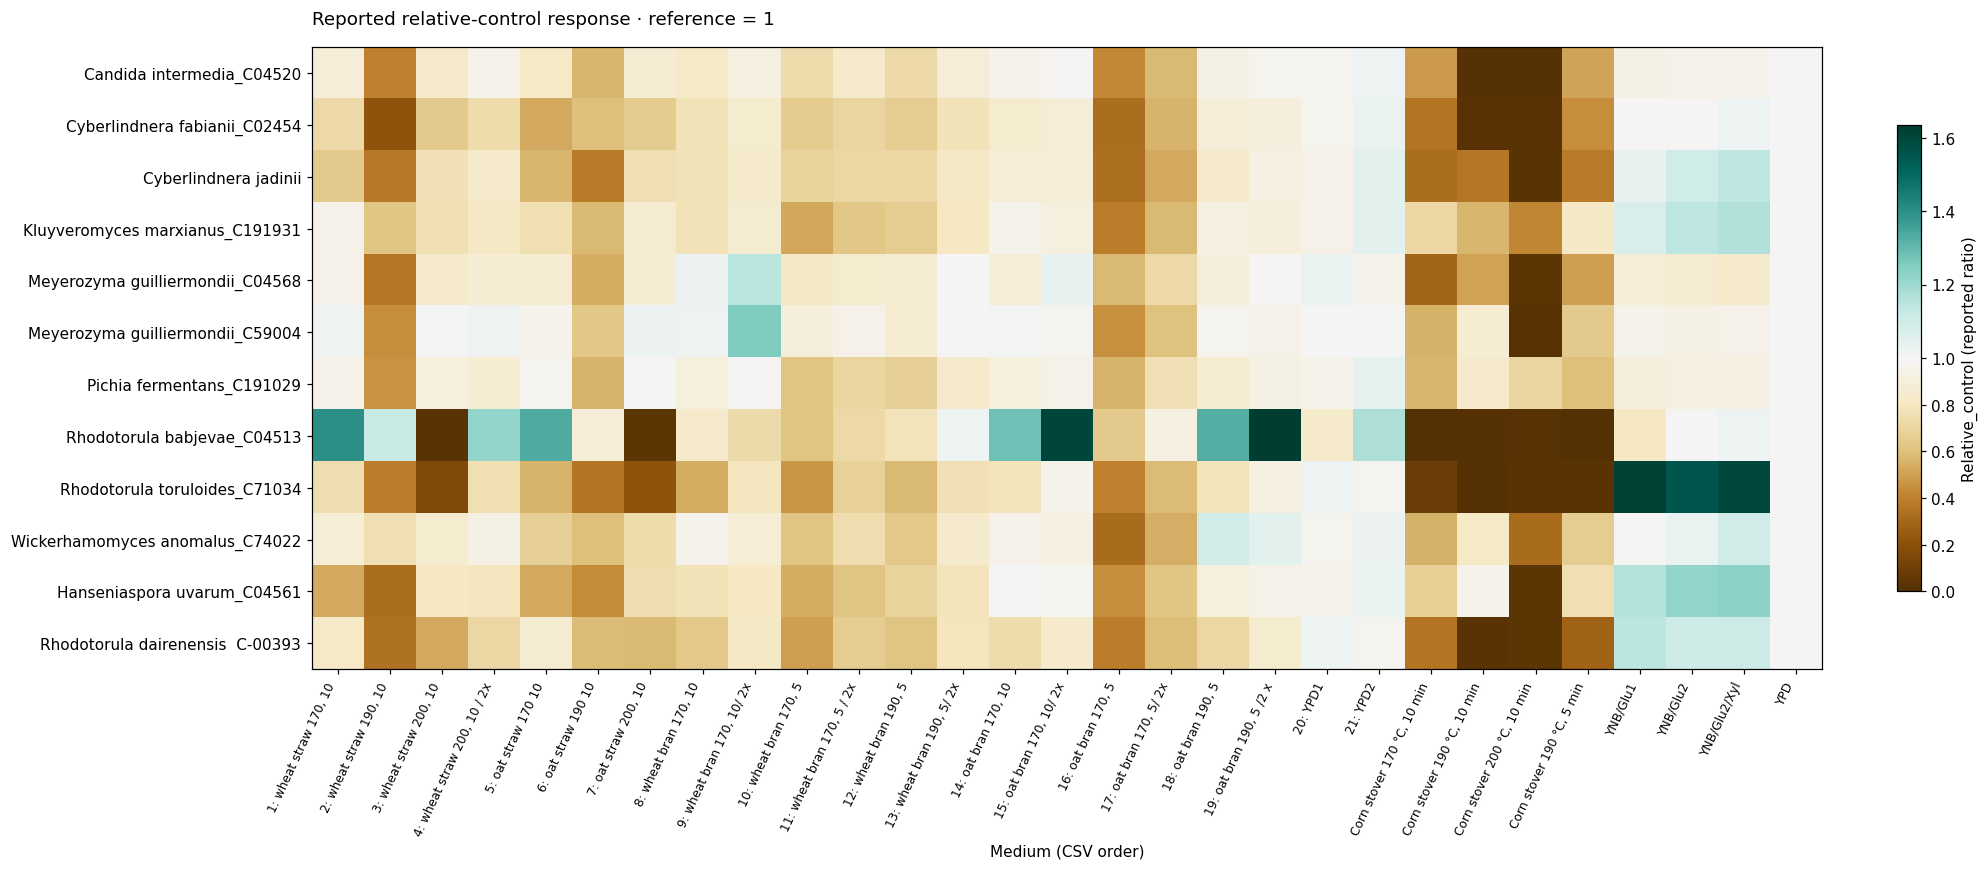

In [3]:
growth_heatmap("Relative_control", "Reported relative-control response · reference = 1", relative=True)

### Read the medium labels

These labels describe feedstocks, processing, dilution variants, and YPD/YNB conditions. They do not give complete medium recipes. `Temperature` and `Time` appear to describe pretreatment, not cultivation. The corn-stover label “200 °C, 10 min” conflicts with its recorded `Time=5`; both are preserved.

In [4]:
medium_data = data.drop_duplicates("medium_id").set_index("medium_id").reindex(media_order)
medium_registry = medium_data[process_columns].reset_index()
show_table(medium_registry)

medium_id,Temperature,Time,Dilution
"Medium 1 (wheat straw 170, 10)",170,10,0.0
"Medium 2(wheat straw 190, 10)",190,10,0.0
"Medium 3 (wheat straw 200, 10)",200,10,0.0
"Medium 4(wheat straw 200, 10 / 2x)",200,10,0.5
Medium 5(oat straw 170 10),170,10,0.0
Medium 6(oat straw 190 10),190,10,0.0
"Medium 7(oat straw 200, 10)",200,10,0.0
"Medium 8(wheat bran 170, 10)",170,10,0.0
"Medium 9(wheat bran 170, 10/ 2x)",170,10,0.5
"Medium 10(wheat bran 170, 5)",170,5,0.0


## 3. What is recorded about medium composition?

Each row below is **one medium**, rather than 12 repeated organism rows. Each chemical has its **own minimum–maximum scale across media**: 0 = its lowest recorded value, 1 = its highest. A column that is constant is shown in grey. This reveals composition patterns; colours do not compare absolute quantities between chemicals.

Chemical units are absent and may differ between columns. Zero means a recorded zero, not a detection-limit claim. These 25 fields are not a complete recipe: an unlisted nutrient is not necessarily absent, and chemical values are not model uptake bounds. Original column spellings are preserved (`manose` was confirmed to mean mannose).

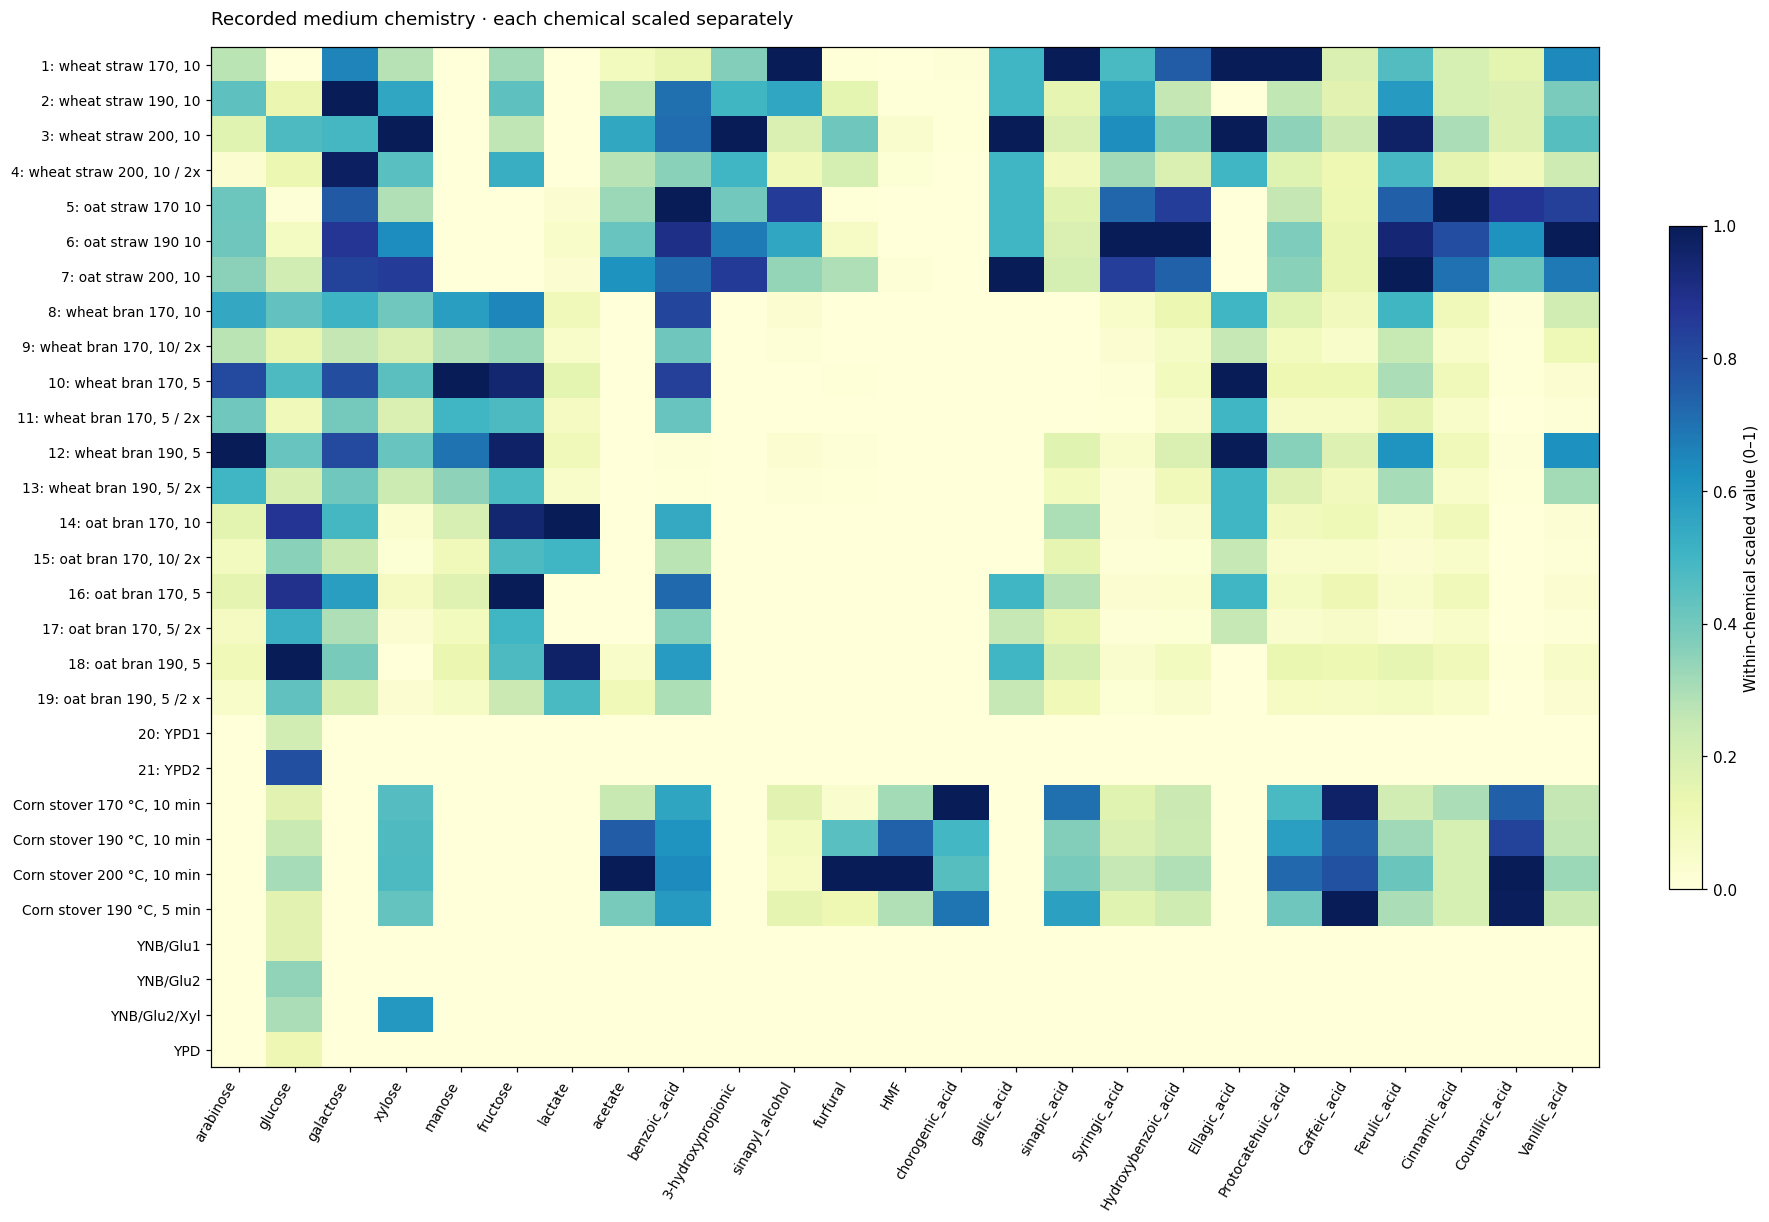

Chemical (source label),Minimum recorded,Maximum recorded,Units
arabinose,0.00,6.26,Not supplied
glucose,9.29,82.98,Not supplied
galactose,0.00,0.98,Not supplied
xylose,0.00,29.65,Not supplied
manose,0.00,0.76,Not supplied
fructose,0.00,0.57,Not supplied
lactate,0.00,5.92,Not supplied
acetate,0.00,1.88,Not supplied
benzoic_acid,0.00,11.10,Not supplied
3-hydroxypropionic,0.00,38.30,Not supplied


In [5]:
chemistry = medium_data[chemical_columns]
chemical_ranges = chemistry.max() - chemistry.min()
scaled_chemistry = (chemistry - chemistry.min()).div(chemical_ranges.replace(0, np.nan))
fig, ax = plt.subplots(figsize=(16, 11), layout="constrained")
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#cccccc")
im = ax.imshow(scaled_chemistry.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(chemical_columns)), chemical_columns, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(media_order)), medium_labels, fontsize=9)
ax.set_title("Recorded medium chemistry · each chemical scaled separately", loc="left", pad=15)
fig.colorbar(im, ax=ax, shrink=0.65, label="Within-chemical scaled value (0–1)")
plt.show()
show_table(pd.DataFrame({"Chemical (source label)": chemical_columns,
                         "Minimum recorded": chemistry.min().to_numpy(),
                         "Maximum recorded": chemistry.max().to_numpy(),
                         "Units": "Not supplied"}))

## 4. Inspect exact growth values for one organism

Edit `selected_organism` and `selected_metric`, then rerun the next cell. All eight growth-summary columns are available, but their definitions differ and they should not be pooled. Grey “missing” labels denote unavailable numeric fits, not zero. The table preserves the original text for the selected metric.

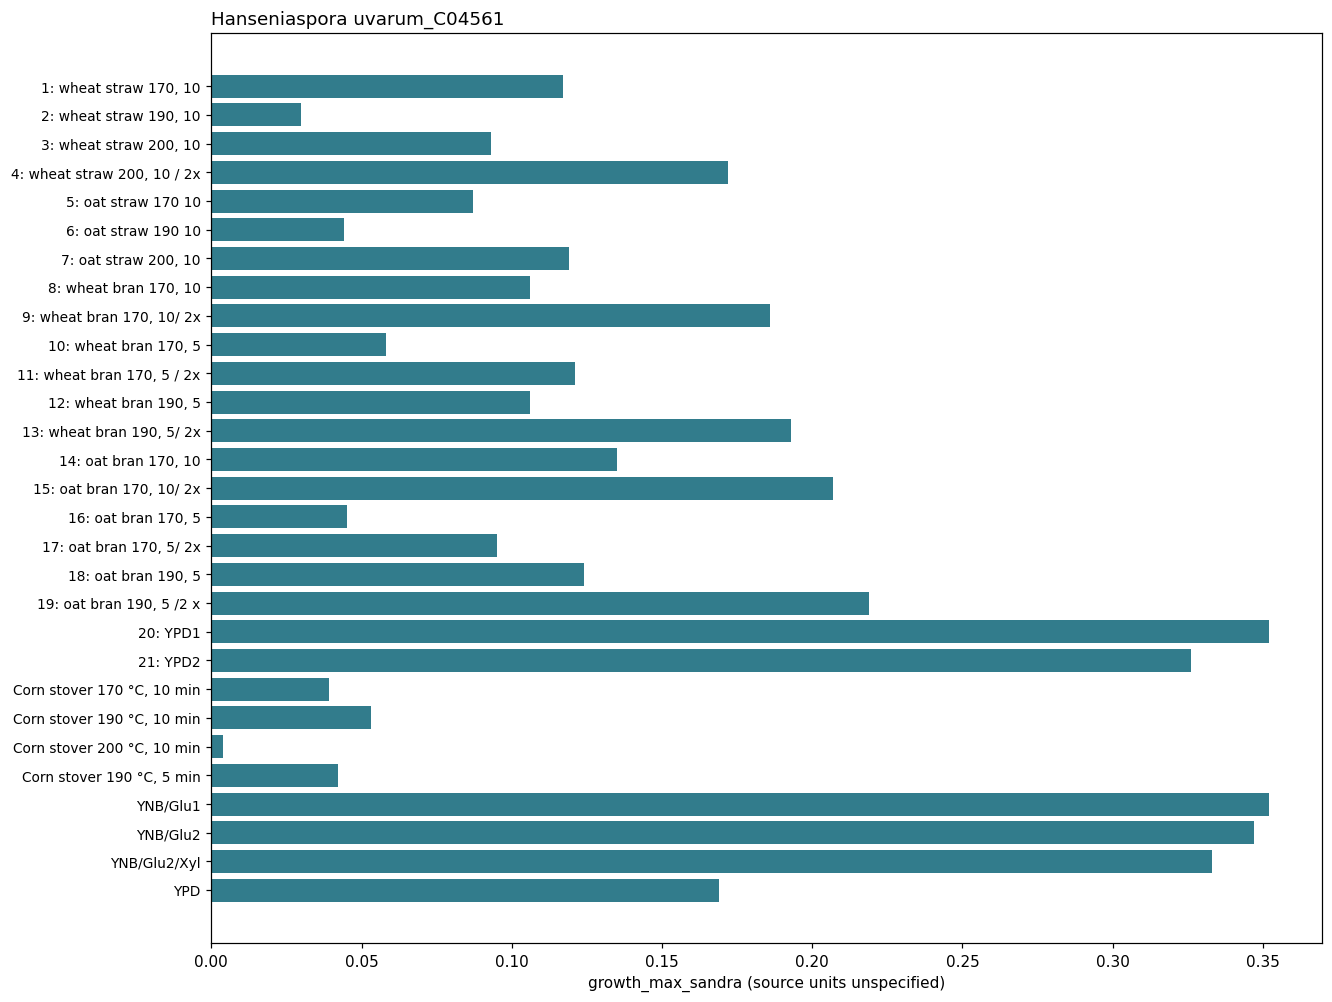

Medium,Selected metric,Original value,Original growth fit failed
"Medium 1 (wheat straw 170, 10)",growth_max_sandra,0.117,False
"Medium 2(wheat straw 190, 10)",growth_max_sandra,0.030,False
"Medium 3 (wheat straw 200, 10)",growth_max_sandra,0.093,False
"Medium 4(wheat straw 200, 10 / 2x)",growth_max_sandra,0.172,False
Medium 5(oat straw 170 10),growth_max_sandra,0.087,False
Medium 6(oat straw 190 10),growth_max_sandra,0.044,False
"Medium 7(oat straw 200, 10)",growth_max_sandra,0.119,False
"Medium 8(wheat bran 170, 10)",growth_max_sandra,0.106,False
"Medium 9(wheat bran 170, 10/ 2x)",growth_max_sandra,0.186,False
"Medium 10(wheat bran 170, 5)",growth_max_sandra,0.058,False


In [6]:
selected_organism = "Hanseniaspora uvarum_C04561"
selected_metric = "growth_max_sandra"

if selected_organism not in organisms or selected_metric not in response_columns:
    raise ValueError("Choose an organism_id from the overview and a metric from response_columns.")
selected = data.loc[data.organism_id.eq(selected_organism)].set_index("medium_id").reindex(media_order)
source_selected = raw_data.loc[raw_data.organism_id.eq(selected_organism)].set_index("medium_id").reindex(media_order)
values = selected[selected_metric]
fig, ax = plt.subplots(figsize=(12, 9), layout="constrained")
ax.barh(np.arange(len(values)), values.fillna(0), color="#327c8c")
for row in np.flatnonzero(values.isna()):
    ax.text(0, row, "missing", color="#666666", va="center")
if selected_metric == "Relative_control":
    ax.axvline(1, color="#666666", linestyle="--", linewidth=1)
ax.set_yticks(range(len(media_order)), medium_labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(selected_metric + " (reported ratio)" if selected_metric == "Relative_control"
              else selected_metric + " (source units unspecified)")
ax.set_title(selected_organism, loc="left")
plt.show()
show_table(pd.DataFrame({"Medium": media_order,
                         "Selected metric": selected_metric,
                         "Original value": source_selected[selected_metric].to_numpy(),
                         "Original growth fit failed": source_selected["growth_max"].eq("cannot fit data").to_numpy()}))

## Reading limits and source checks

The dataset can show reported responses and composition patterns. It does not supply replicate IDs, uncertainty estimates, flux measurements, or raw growth time series. Associations between chemicals and growth would be exploratory because feedstock and pretreatment change several chemicals together.

The checks below expose failed fits and the metadata discrepancy without replacing source values. Detailed interpretation and provenance are in [the fungi working notes](docs/working_notes/fungi_experiment_notes.md).

In [7]:
fit_failures = raw_data.loc[original_fit_failed, ["organism_id", "medium_id", "growth_max", "growth_max_sandra"]]
print(f"Original growth_max fit failures: {len(fit_failures)} of {len(data)} rows.")
show_table(fit_failures)
metadata_conflict = medium_registry.loc[medium_registry.medium_id.eq("Corn stover (FIN), 200 °C, 10 min")]
print("Medium-label / Time-field discrepancy (source values preserved):")
show_table(metadata_conflict)
assert data["growth_max"].isna().equals(original_fit_failed)
assert raw_data.equals(pd.read_csv(csv_path)), "Source data unexpectedly changed."

Original growth_max fit failures: 18 of 348 rows.


organism_id,medium_id,growth_max,growth_max_sandra
Candida intermedia_C04520,"Corn stover (FIN), 190 °C, 10 min",cannot fit data,0.001
Candida intermedia_C04520,"Corn stover (FIN), 200 °C, 10 min",cannot fit data,0.002
Cyberlindnera fabianii_C02454,"Corn stover (FIN), 190 °C, 10 min",cannot fit data,0.002
Cyberlindnera fabianii_C02454,"Corn stover (FIN), 200 °C, 10 min",cannot fit data,0.001
Cyberlindnera jadinii,"Corn stover (FIN), 200 °C, 10 min",cannot fit data,0.002
Meyerozyma guilliermondii_C04568,"Corn stover (FIN), 200 °C, 10 min",cannot fit data,0.003
Meyerozyma guilliermondii_C59004,"Corn stover (FIN), 200 °C, 10 min",cannot fit data,0.003
Rhodotorula babjevae_C04513,"Corn stover (FIN), 170 °C, 10 min",cannot fit data,0.000
Rhodotorula babjevae_C04513,"Corn stover (FIN), 190 °C, 10 min",cannot fit data,0.001
Rhodotorula babjevae_C04513,"Corn stover (FIN), 200 °C, 10 min",cannot fit data,0.002


Medium-label / Time-field discrepancy (source values preserved):


medium_id,Temperature,Time,Dilution
"Corn stover (FIN), 200 °C, 10 min",200,5,0.0
